In [45]:
import numpy as np
import pandas as pd
import os
from sklearn.model_selection import train_test_split
import xgboost as xgb
from sklearn.feature_extraction import DictVectorizer
import seaborn as sns
from sklearn.metrics import mutual_info_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix, classification_report, accuracy_score, roc_curve, roc_auc_score, ConfusionMatrixDisplay
os.chdir(r"D:\Virtual Environments\ML zoomcamp\Data") # Change according to your file directory

# Part 0: Introduction

# Part 1: EDA

In [6]:
df = pd.read_csv('diabetes-dataset-2k.csv')
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,0.32,0,0,No Info,20.56,6.6,126,0
1,Male,21.00,0,0,never,23.78,6.0,126,0
2,Female,15.00,0,0,never,16.27,6.0,160,0
3,Male,34.00,0,0,never,37.43,6.1,85,0
4,Female,44.00,0,0,former,23.49,4.5,80,0


In [14]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

No missing or null variables in the dataset

In [7]:
df.shape

(2000, 9)

In [8]:
df.dtypes

gender                     str
age                    float64
hypertension             int64
heart_disease            int64
smoking_history            str
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

In [9]:
df.nunique()

gender                    2
age                      98
hypertension              2
heart_disease             2
smoking_history           6
bmi                    1108
HbA1c_level              18
blood_glucose_level      18
diabetes                  2
dtype: int64

In [10]:
df['diabetes'].value_counts(normalize=True)

diabetes
0    0.915
1    0.085
Name: proportion, dtype: float64

From the dataset, 91.5% of individuals do not have diabetes while 8.5% of individuals have diabetes. Given the vast difference in proportions, it will be important to consider stratifying the data when splitting.

In [7]:
df['smoking_history'] = df['smoking_history'].mask((df['smoking_history'] == 'current') |
                                                   (df['smoking_history'] == 'ever') |
                                                   (df['smoking_history'] == 'former'), 'yes')
df['smoking_history'] = df['smoking_history'].mask((df['smoking_history'] == 'never') |
                                                   (df['smoking_history'] == 'not current'), 'no')
df['smoking_history'] = df['smoking_history'].str.lower()

The response variable, diabetes, will be the target output that the model will be trying to predict. It has been changed to string whereby '0' represents no diabetes and '1' represents diabetes present. For simplicity, we will be categorising the variables in 'smoking_history' into 'yes', 'no' and 'no info'

## Checking The Association between response and input variables

In [15]:
corr_matrix = df.corr(numeric_only=True)
print(corr_matrix.round(2))

                      age  hypertension  heart_disease   bmi  HbA1c_level  \
age                  1.00          0.26           0.23  0.34         0.08   
hypertension         0.26          1.00           0.17  0.13         0.08   
heart_disease        0.23          0.17           1.00  0.07         0.07   
bmi                  0.34          0.13           0.07  1.00         0.08   
HbA1c_level          0.08          0.08           0.07  0.08         1.00   
blood_glucose_level  0.11          0.04           0.06  0.14         0.20   
diabetes             0.24          0.15           0.21  0.23         0.42   

                     blood_glucose_level  diabetes  
age                                 0.11      0.24  
hypertension                        0.04      0.15  
heart_disease                       0.06      0.21  
bmi                                 0.14      0.23  
HbA1c_level                         0.20      0.42  
blood_glucose_level                 1.00      0.41  
diabetes    

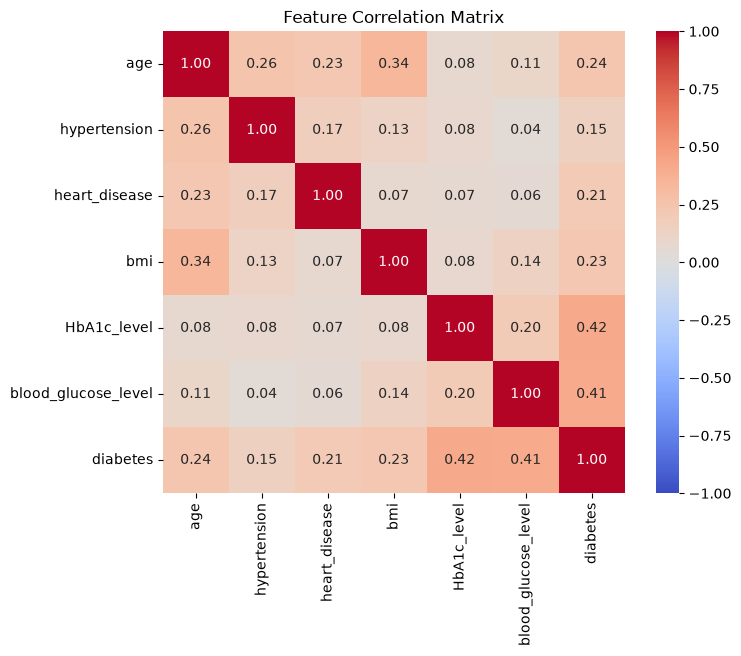

In [18]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,        
    fmt=".2f",         
    cmap="coolwarm",   
    vmin=-1, vmax=1,   
    square=True        
)
plt.title("Feature Correlation Matrix")
plt.show()

Some noticeable observations include moderate correlations between blood_glucose_level and diabetes (0.41), and between HbA1c_level and diabetes (0.42). The other variables display weak correlations with one another (below 0.30). There were no negative correlations.

In [ ]:
def mutual_info_diabetes_score(series):
    return mutual_info_score(series, df_full_train['diabetes'])


mi = df_full_train[categorical].apply(mutual_info_diabetes_score)


mi = mi.sort_values(ascending=False)
print(mi)

# Part 2: Methods

Logistic Regression vs XGBoost


## Splitting Dataset to form Test and Train splits

In [23]:
df_full_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=1101,
    stratify=df['diabetes']
)

df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=1101,
    stratify=df_full_train['diabetes']
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

response = 'diabetes'
numerical = ['age', 'bmi', 'blood_glucose_level', 'HbA1c_level']
categorical = ['hypertension', 'heart_disease', 'smoking_history', 'gender']

y_train = df_train[response].values
y_val = df_val[response].values

In [24]:
train_dicts = df_train[categorical + numerical].to_dict(orient='records')
val_dicts = df_val[categorical + numerical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

In [47]:
thresholds = np.arange(0.01, 1.00, 0.01)
best_threshold = 0.5
best_f1 = 0

for t in thresholds:
    y_val_bin = (y_val_pred >= t).astype(int)
    f1 = f1_score(y_val, y_val_bin, zero_division=0)
    if f1 > best_f1:
        best_f1 = f1
        best_threshold = t

print(f"Best Threshold: {best_threshold:.2f} with F1-Score: {best_f1:.4f}")

Best Threshold: 0.52 with F1-Score: 0.7931


## XGBoost

In [25]:
features = list(dv.get_feature_names_out())

dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

In [29]:
#Setting a baseline model
params = {
    'eta': 0.3,              
    'max_depth': 6,          
    'min_child_weight': 1,   
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'nthread': 8,
    'seed': 1101
}

watchlist = [(dtrain, 'train'), (dval, 'val')]

model = xgb.train(
    params,
    dtrain,
    num_boost_round=100,
    evals=watchlist,
    verbose_eval=5
)

[0]	train-auc:0.95171	val-auc:0.94270
[5]	train-auc:0.98834	val-auc:0.97356
[10]	train-auc:0.99232	val-auc:0.97786
[15]	train-auc:0.99586	val-auc:0.97730
[20]	train-auc:0.99848	val-auc:0.97830
[25]	train-auc:0.99971	val-auc:0.97814
[30]	train-auc:0.99996	val-auc:0.98055
[35]	train-auc:1.00000	val-auc:0.98168
[40]	train-auc:1.00000	val-auc:0.98128
[45]	train-auc:1.00000	val-auc:0.98160
[50]	train-auc:1.00000	val-auc:0.98071
[55]	train-auc:1.00000	val-auc:0.98160
[60]	train-auc:1.00000	val-auc:0.98152
[65]	train-auc:1.00000	val-auc:0.98055
[70]	train-auc:1.00000	val-auc:0.97903
[75]	train-auc:1.00000	val-auc:0.97903
[80]	train-auc:1.00000	val-auc:0.97903
[85]	train-auc:1.00000	val-auc:0.97838
[90]	train-auc:1.00000	val-auc:0.97798
[95]	train-auc:1.00000	val-auc:0.97758
[99]	train-auc:1.00000	val-auc:0.97710


In [30]:
scores = {}

for max_depth in [3, 4, 6, 10]:
    for min_child_weight in [1, 5, 10]:
        
        params = {
            'eta': 0.1,
            'max_depth': max_depth,
            'min_child_weight': min_child_weight,
            'objective': 'binary:logistic',
            'eval_metric': 'auc',
            'seed': 1101
        }
        
        # Train model over 100 rounds
        model = xgb.train(params, dtrain, num_boost_round=100, evals=watchlist, verbose_eval=False)
        
        # Predict on validation set
        y_pred = model.predict(dval)
        auc = roc_auc_score(y_val, y_pred)
        
        key = f"depth_{max_depth}_min_child_{min_child_weight}"
        scores[key] = auc
        print(f"{key} -> val AUC: {auc:.4f}")

# Find the configuration with the highest validation AUC
best_config = max(scores, key=scores.get)
print(f"\nBest Configuration: {best_config} with AUC: {scores[best_config]:.4f}")

depth_3_min_child_1 -> val AUC: 0.9722
depth_3_min_child_5 -> val AUC: 0.9648
depth_3_min_child_10 -> val AUC: 0.9473
depth_4_min_child_1 -> val AUC: 0.9734
depth_4_min_child_5 -> val AUC: 0.9636
depth_4_min_child_10 -> val AUC: 0.9496
depth_6_min_child_1 -> val AUC: 0.9802
depth_6_min_child_5 -> val AUC: 0.9655
depth_6_min_child_10 -> val AUC: 0.9506
depth_10_min_child_1 -> val AUC: 0.9789
depth_10_min_child_5 -> val AUC: 0.9664
depth_10_min_child_10 -> val AUC: 0.9506

Best Configuration: depth_6_min_child_1 with AUC: 0.9802


In [31]:
scores = {}

for eta in [0.3, 0.1, 0.05, 0.01]:
    
    params = {
        'eta': eta,
        'max_depth': 6,          
        'min_child_weight': 1,   
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'seed': 1101             
    }
    
    model = xgb.train(params, dtrain, num_boost_round=100, evals=watchlist, verbose_eval=False)
    
    y_pred = model.predict(dval)
    auc = roc_auc_score(y_val, y_pred)
    
    scores[eta] = auc
    print(f"eta: {eta} -> val AUC: {auc:.4f}")

best_eta = max(scores, key=scores.get)
print(f"\nBest eta: {best_eta} with AUC: {scores[best_eta]:.4f}")

eta: 0.3 -> val AUC: 0.9771
eta: 0.1 -> val AUC: 0.9802
eta: 0.05 -> val AUC: 0.9777
eta: 0.01 -> val AUC: 0.9612

Best eta: 0.1 with AUC: 0.9802


In [32]:
final_params = {
    'eta': 0.1,
    'max_depth': 6,
    'min_child_weight': 1,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'seed': 1101
}

In [35]:
full_train_dicts = df_full_train[categorical + numerical].to_dict(orient='records')
test_dicts = df_test[categorical + numerical].to_dict(orient='records')

X_full_train = dv.fit_transform(full_train_dicts)
X_test = dv.transform(test_dicts)

y_full_train = df_full_train[response].values
y_test = df_test[response].values

features = list(dv.get_feature_names_out())
dfulltrain = xgb.DMatrix(X_full_train, label=y_full_train, feature_names=features)
dtest = xgb.DMatrix(X_test, label=y_test, feature_names=features)

In [37]:
final_model = xgb.train(
    final_params,
    dfulltrain,
    num_boost_round=100
)
y_test_pred = final_model.predict(dtest)
final_test_auc = roc_auc_score(y_test, y_test_pred)
print(f"Final Test ROC AUC: {final_test_auc:.4f}")

Final Test ROC AUC: 0.9541


In [49]:
y_test_pred_xgb_binary = (y_test_pred >= 0.52).astype(int)

print("Classification Report:")
print(classification_report(y_test, y_test_pred_xgb_binary))

Confusion Matrix:
[[365   1]
 [ 12  22]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       366
           1       0.96      0.65      0.77        34

    accuracy                           0.97       400
   macro avg       0.96      0.82      0.88       400
weighted avg       0.97      0.97      0.96       400



## Logistic Regression

In [22]:
def mutual_info_diabetes_score(series):
    return mutual_info_score(series, df_full_train['diabetes'])

mi = df_full_train[categorical].apply(mutual_info_diabetes_score)

mi = mi.sort_values(ascending=False)
print(mi)

heart_disease      0.015784
smoking_history    0.011702
hypertension       0.004310
gender             0.001746
dtype: float64


In [39]:
lr_model = LogisticRegression(solver='liblinear', random_state=1101, max_iter=1000)
lr_model.fit(X_full_train, y_full_train)
y_pred_lr = lr_model.predict_proba(X_test)[:, 1]

lr_test_auc = roc_auc_score(y_test, y_pred_lr)
print(f"Logistic Regression Test ROC AUC: {lr_test_auc:.4f}")

Logistic Regression Test ROC AUC: 0.9465


In [41]:
scores = {}
C_values = [0.001, 0.01, 0.1, 1, 10, 100]

for c in C_values:
    lr_tuned = LogisticRegression(solver='liblinear', C=c, random_state=1101, max_iter=1000)
    lr_tuned.fit(X_train, y_train)
    y_val_pred = lr_tuned.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_val_pred)
    scores[c] = auc
    print(f"C: {c} -> val AUC: {auc:.4f}")

best_c = max(scores, key=scores.get)
print(f"\nBest C: {best_c} with AUC: {scores[best_c]:.4f}")

C: 0.001 -> val AUC: 0.4673
C: 0.01 -> val AUC: 0.5416
C: 0.1 -> val AUC: 0.8110
C: 1 -> val AUC: 0.9459
C: 10 -> val AUC: 0.9521
C: 100 -> val AUC: 0.9505

Best C: 10 with AUC: 0.9521


In [43]:
final_lr_model = LogisticRegression(solver='liblinear', C=10, random_state=1101, max_iter=1000)
final_lr_model.fit(X_full_train, y_full_train)
y_pred_lr = lr_model.predict_proba(X_test)[:, 1]

lr_test_auc = roc_auc_score(y_test, y_pred_lr)
print(f"Logistic Regression Test ROC AUC: {lr_test_auc:.4f}")

Logistic Regression Test ROC AUC: 0.9465


In [53]:
y_test_pred_lr = (y_pred_lr >= 0.52).astype(int)

print("Classification Report:")
print(classification_report(y_test, y_test_pred_lr))

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       366
           1       0.93      0.38      0.54        34

    accuracy                           0.94       400
   macro avg       0.94      0.69      0.76       400
weighted avg       0.94      0.94      0.93       400

